# Módulo D: Interpretabilidad e integración

> **Adaptación acordada:** el enunciado plantea SHAP sobre el Módulo A (clasificación). Como el equipo
> desarrolla los módulos 0, B y D, aquí se interpreta el **modelo LightGBM del Módulo B** (pronóstico de
> órdenes diarias con rezagos, medias móviles y calendario) y se integra con los datos del Módulo 0.

1. **SHAP sobre el modelo de B:** importancia global (beeswarm), dependencia de las 3 variables más
   relevantes y explicación local de un pronóstico acertado y de uno con gran error (el análogo del par
   "orden detectada / falso negativo" del enunciado). Se contrasta con la importancia por permutación.
2. **Integración:** de las órdenes pronosticadas por B a un plan semanal de despachos por estado de origen
   de los vendedores, validado contra los despachos reales.
3. **Caso de uso y limitaciones.**

**Responsable:** _(nombre)_

In [1]:
# Configuración común: imports, conexión solo lectura y estilo de gráficos
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from olist import conectar, consulta, RANDOM_STATE
from olist import config
from olist.graficos import estilo, guardar
from olist import series as ts

import joblib
import shap
from sklearn.inspection import permutation_importance

estilo()
np.random.seed(RANDOM_STATE)
con = conectar()  # read_only=True: la base cruda no se modifica

## 0. Datos y modelo del Módulo B

Se carga el artefacto que guarda `B_series.ipynb`: el LightGBM elegido en validación, entrenado **solo
con datos anteriores a la prueba**, su estrategia multi-paso y el cuantil conformal del 90 %.

In [2]:
df = consulta(con, "B_series/serie_diaria.sql", [config.FECHA_INICIO_UTIL, config.FECHA_FIN_UTIL])
y = df.set_index(pd.DatetimeIndex(df["fecha"]).rename("fecha"))["ordenes"].astype(float).asfreq("D")
y_trval, y_prueba = ts.separar_prueba(y)

ruta_modelo = config.MODELS_DIR / "lightgbm_series.joblib"
if not ruta_modelo.exists():
    raise FileNotFoundError("Ejecute primero notebooks/B_series.ipynb: genera models/lightgbm_series.joblib")
artefacto = joblib.load(ruta_modelo)
modelo = artefacto["modelo"]
estrategia = artefacto["estrategia"]
if pd.Timestamp(artefacto["fecha_corte_entrenamiento"]) != y_trval.index.max():
    raise ValueError("El modelo guardado no corresponde al período útil actual: vuelva a ejecutar B_series.ipynb")

print(f"Estrategia: {estrategia} | entrenado hasta {y_trval.index.max().date()} | "
      f"prueba: {y_prueba.index.min().date()} a {y_prueba.index.max().date()}")
print("Hiperparámetros:", artefacto["parametros"])
print(f"Variables ({len(artefacto['features'])}):", ", ".join(artefacto["features"]))

Estrategia: directo | entrenado hasta 2018-06-26 | prueba: 2018-06-27 a 2018-08-21
Hiperparámetros: {'n_estimators': 250, 'learning_rate': 0.03, 'num_leaves': 7, 'min_child_samples': 20}
Variables (22): lag_1, lag_2, lag_3, lag_7, lag_14, lag_21, lag_28, media_7, desv_7, media_14, desv_14, media_28, desv_28, dia_semana, dia_mes, mes, semana_anio, fin_de_semana, festivo, dias_a_black_friday, semana_black_friday, horizonte


## 1. Conjunto que se explica

El modelo se explica sobre sus pronósticos **en el período de prueba**, que no usó para entrenar ni para
elegir hiperparámetros.

- Con la estrategia **directa**, el modelo fijo se aplica desde cada origen posible dentro de la prueba
  (como si se emitiera un pronóstico cada día), con horizontes de 1 a 28 días. Cada fila usa solo los
  datos observados hasta su origen.
- Con la estrategia **recursiva**, cada día de prueba se pronostica a un paso con los rezagos reales.

Así hay suficientes filas, con rezagos y horizontes variados, para que SHAP muestre qué mueve el pronóstico.

In [3]:
def matriz_explicacion(serie, estrategia):
    """Filas de pronóstico cuyo objetivo cae en la prueba, con datos disponibles en su origen."""
    if estrategia == "directo":
        X, objetivo = ts.matriz_supervisada_directa(serie)
        origenes = X.index.get_level_values("origen")
        fechas_objetivo = X.index.get_level_values("fecha_objetivo")
        mascara = (origenes >= y_trval.index.max()) & fechas_objetivo.isin(y_prueba.index)
    else:
        X, objetivo = ts.matriz_supervisada(serie)
        mascara = X.index.isin(y_prueba.index)
    return X[mascara], objetivo[mascara]

X_exp, y_exp = matriz_explicacion(y, estrategia)
X_exp = X_exp[modelo.feature_name_]  # mismo orden de columnas que en el entrenamiento
pred_exp = pd.Series(modelo.predict(X_exp), index=X_exp.index).clip(lower=0)
print(f"Filas explicadas: {len(X_exp)}")
print("Métricas del modelo en estas filas:", {k: round(v, 2) for k, v in ts.metricas(y_exp, pred_exp).items()})

if estrategia == "directo":
    semana_h = "semana " + ((X_exp["horizonte"] - 1) // 7 + 1).astype(str)
    display(pd.DataFrame({"y": y_exp.to_numpy(), "yhat": pred_exp.to_numpy(), "semana": semana_h.to_numpy()})
            .groupby("semana")[["y", "yhat"]]
            .apply(lambda g: pd.Series(ts.metricas(g["y"], g["yhat"]))).round(2))

Filas explicadas: 1190
Métricas del modelo en estas filas: {'MAE': 60.2, 'RMSE': 69.01, 'sMAPE': 26.27}


,MAE,RMSE,sMAPE
semana,,,
semana 1,57.71,67.00,26.37
semana 2,60.99,69.49,27.30
semana 3,59.46,68.40,24.88
semana 4,64.08,72.28,26.32


## 2. SHAP: importancia global

`TreeExplainer` calcula, para cada fila, cuánto suma o resta cada variable al pronóstico respecto del
valor base (el pronóstico medio del modelo).

Valor base (pronóstico medio del modelo): 168.9 órdenes


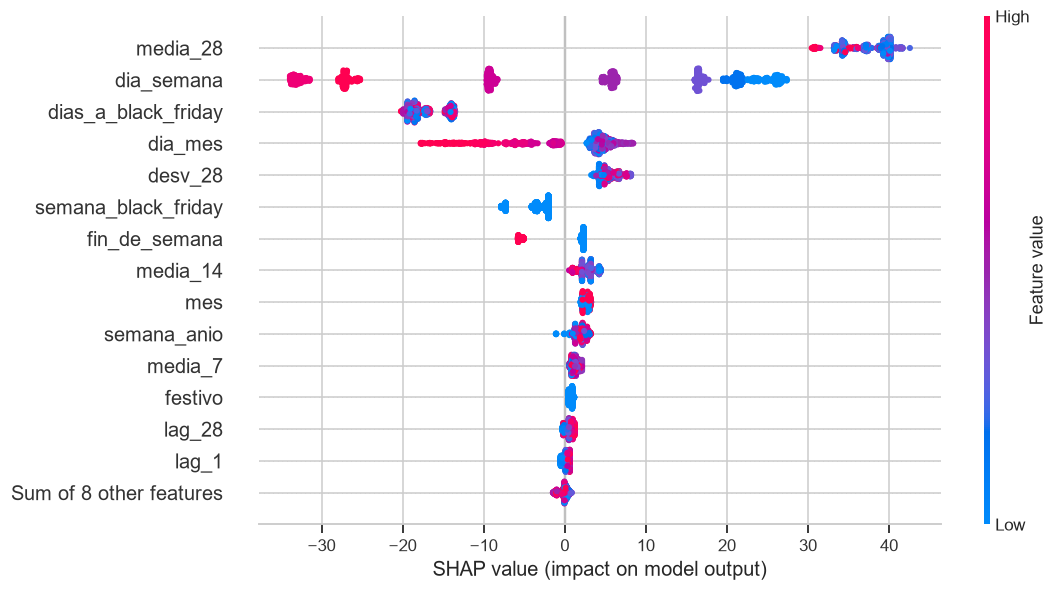

media_28               37.52
dia_semana             19.93
dias_a_black_friday    17.23
dia_mes                 5.53
desv_28                 5.31
semana_black_friday     3.35
fin_de_semana           3.19
media_14                2.75
mes                     2.68
semana_anio             2.11
Name: shap_medio_abs, dtype: float64

In [4]:
explicador = shap.TreeExplainer(modelo)
shap_exp = explicador(X_exp)
print(f"Valor base (pronóstico medio del modelo): {float(np.ravel(explicador.expected_value)[0]):.1f} órdenes")

shap.plots.beeswarm(shap_exp, max_display=15, show=False)
fig = plt.gcf()
fig.set_size_inches(10, 6)
guardar(fig, "shap_beeswarm", "D_integracion")
display(fig)
plt.close(fig)

importancia_shap = pd.Series(np.abs(shap_exp.values).mean(axis=0), index=X_exp.columns) \
    .sort_values(ascending=False).rename("shap_medio_abs")
importancia_shap.head(10).round(2)

**Lectura.** El valor base es de 169 órdenes: es el pronóstico medio sobre el entrenamiento, que incluye
el 2017 de baja demanda. Tres variables explican casi todo el pronóstico en la prueba:

- `media_28` (nivel de las últimas 4 semanas) suma entre +31 y +42 órdenes en **todas** las filas: corrige
  el nivel de 2017 al de 2018.
- `dia_semana` reproduce el ciclo semanal: los lunes suman unas +25 órdenes y los sábados restan unas −33.
- `dias_a_black_friday` resta entre −14 y −20 órdenes en todas las filas de julio y agosto.

`dia_mes` aporta un efecto menor: los últimos días del mes restan hasta −17. Los rezagos diarios
(`lag_1`, `lag_7`…) casi no pesan.

### Importancia por familia de variables y horizonte

Las variables se agrupan en rezagos, medias y desviaciones móviles, calendario y horizonte. Así se ve en
qué se apoya el modelo según cuánto pronostica hacia adelante.

In [5]:
def familia(variable):
    if variable.startswith("lag_"):
        return "rezagos"
    if variable.startswith(("media_", "desv_")):
        return "medias y desviaciones"
    if variable == "horizonte":
        return "horizonte"
    return "calendario"

shap_abs = pd.DataFrame(np.abs(shap_exp.values), columns=X_exp.columns, index=X_exp.index)
por_familia = shap_abs.T.groupby(familia).sum().T
if estrategia == "directo":
    por_familia["semana de horizonte"] = ((X_exp["horizonte"] - 1) // 7 + 1).to_numpy()
    tabla_familias = por_familia.groupby("semana de horizonte").mean()
else:
    tabla_familias = por_familia.mean().to_frame("todas las filas").T
display((tabla_familias.div(tabla_familias.sum(axis=1), axis=0) * 100).round(1).add_suffix(" (%)"))

,calendario (%),horizonte (%),medias y desviaciones (%),rezagos (%)
semana de horizonte,,,,
1,53.4,0.1,45.5,1.0
2,53.2,0.1,45.7,1.0
3,53.0,0.1,45.9,0.9
4,53.0,0.1,46.0,0.9


**Lectura.** El calendario aporta cerca del 53 % del SHAP total, las medias y desviaciones móviles el 46 %,
y los rezagos diarios apenas el 1 %, **sin cambios entre la semana 1 y la 4**. El modelo directo no usa el
dato de ayer para el pronóstico de mañana: pronostica "nivel reciente × perfil semanal". Por eso su error
casi no crece con el horizonte (MAE 57,7 en la semana 1 frente a 64,1 en la 4), y por eso tampoco reacciona
rápido a los cambios bruscos de nivel.

El MAE de estas filas (60,2) es mayor que el de la evaluación de B (50,6) porque aquí entran todos los
orígenes diarios de la prueba, incluidos los emitidos durante la caída de julio.

## 3. Dependencia de las 3 variables más relevantes

Top 3 por SHAP medio absoluto: ['media_28', 'dia_semana', 'dias_a_black_friday']


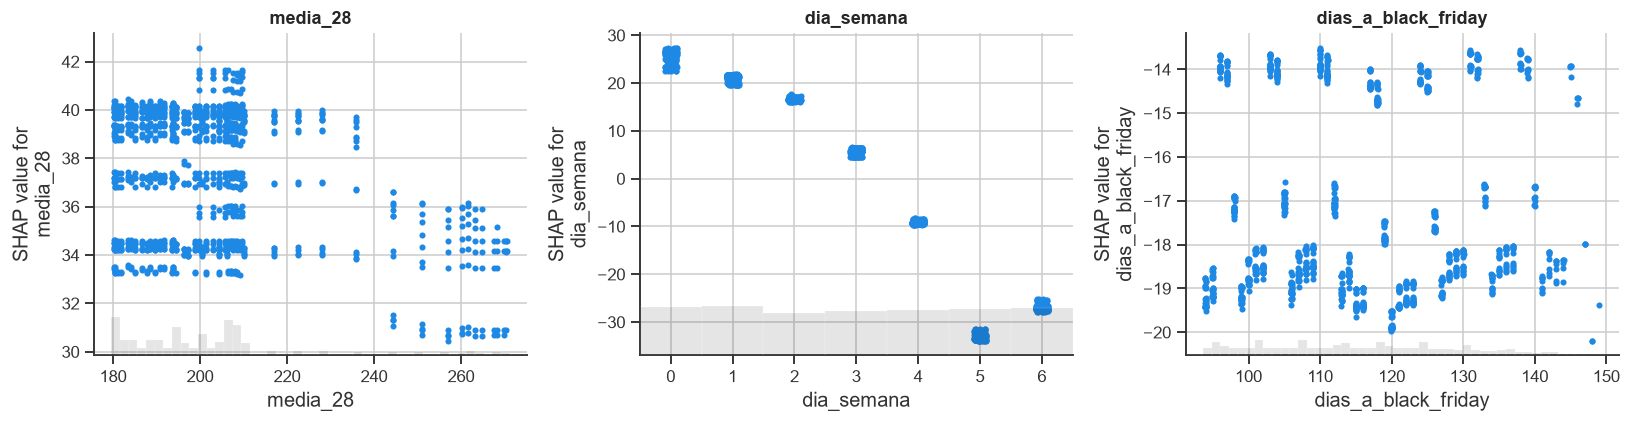

In [6]:
top3 = importancia_shap.index[:3].tolist()
print("Top 3 por SHAP medio absoluto:", top3)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, variable in zip(axes, top3):
    shap.plots.scatter(shap_exp[:, variable], ax=ax, show=False)
    ax.set_title(variable)
fig.tight_layout()
guardar(fig, "shap_dependencia_top3", "D_integracion")
display(fig)
plt.close(fig)

**Lectura.**
- **`media_28`:** el efecto es positivo para todo el rango observado (180 a 270 órdenes), pero **no
  crece** con la media. Por encima de 240 incluso baja (de +40 a +31). Probablemente el modelo aprendió de
  diciembre de 2017, cuando una media alta, inflada por Black Friday, iba seguida de una caída.
- **`dia_semana`:** el efecto es escalonado y muy estable: lunes +25, martes +21, miércoles +17,
  jueves +6, viernes −9, sábado −33 y domingo −27. Es el patrón semanal del Módulo 0.
- **`dias_a_black_friday`:** entre 94 y 150 días antes de Black Friday el efecto es siempre negativo
  (−14 a −20) y sin tendencia. En el entrenamiento esa distancia solo aparece entre fines de junio y
  agosto de 2017, cuando la demanda era menor, y la usa como una estacionalidad anual aprendida de **un solo año**. Es una relación
  espuria: penaliza el pronóstico de 2018 sin una razón de negocio.

## 4. Explicaciones locales

Se toman los dos casos extremos de la prueba: el pronóstico **más acertado** y el de **mayor error**.
Es el análogo de la orden bien detectada y del falso negativo del enunciado.

acertado: emitido el 2018-07-09 para el 2018-07-16 (Monday), horizonte 7 | real=245 | pronóstico=245


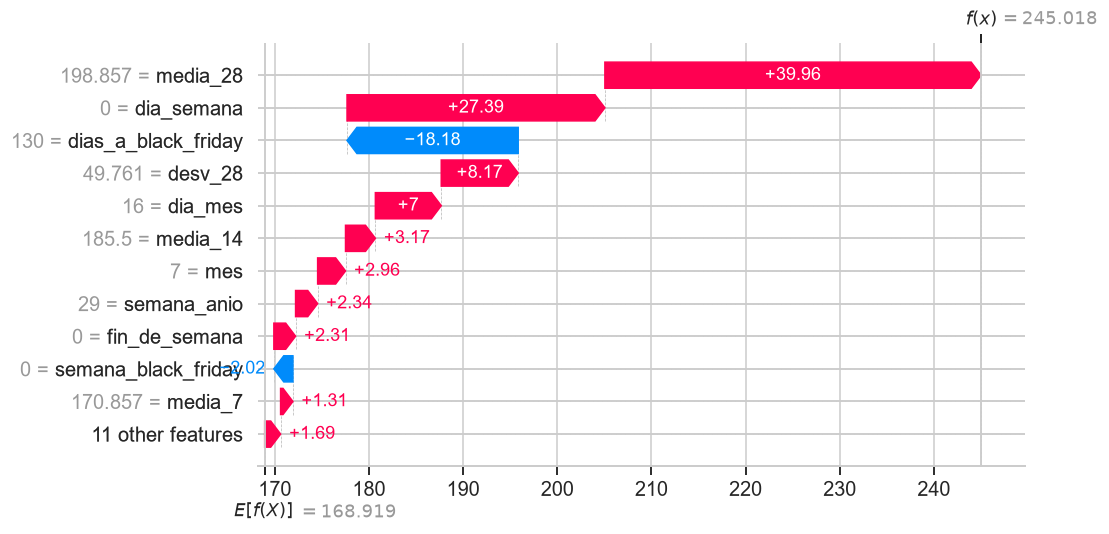

mayor_error: emitido el 2018-07-13 para el 2018-08-07 (Tuesday), horizonte 25 | real=370 | pronóstico=233


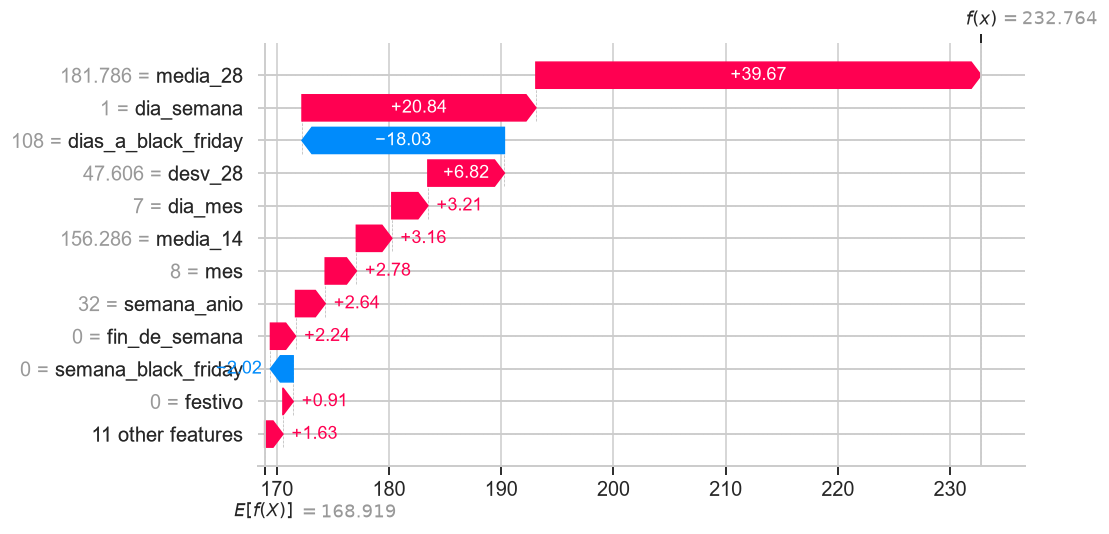

In [7]:
error_abs = (y_exp - pred_exp).abs().to_numpy()
casos = {"acertado": int(np.argmin(error_abs)), "mayor_error": int(np.argmax(error_abs))}
for etiqueta, posicion in casos.items():
    clave = X_exp.index[posicion]
    if estrategia == "directo":
        origen, objetivo = clave
        descripcion = (f"emitido el {origen.date()} para el {objetivo.date()} ({objetivo.day_name()}), "
                       f"horizonte {int(X_exp.iloc[posicion]['horizonte'])}")
    else:
        descripcion = f"día {clave.date()} ({clave.day_name()})"
    print(f"{etiqueta}: {descripcion} | real={y_exp.iloc[posicion]:.0f} | pronóstico={pred_exp.iloc[posicion]:.0f}")
    shap.plots.waterfall(shap_exp[posicion], max_display=12, show=False)
    fig = plt.gcf()
    fig.set_size_inches(9, 5)
    guardar(fig, f"shap_local_{etiqueta}", "D_integracion")
    display(fig)
    plt.close(fig)

**Lectura.**
- **Acertado:** el pronóstico emitido el 9-jul para el lunes 16-jul (horizonte 7) dio 245 órdenes, igual
  al valor real. Se arma con el valor base (169), el nivel (+40), el efecto lunes (+27) y la penalización de
  `dias_a_black_friday` (−18). Acertó porque ese lunes la demanda ya había vuelto a su nivel habitual.
- **Mayor error (el análogo del falso negativo):** el pronóstico emitido el 13-jul para el martes 7-ago
  (horizonte 25) dio 233 órdenes, frente a 370 reales: el día más alto de la prueba. Se emitió en plena caída
  de julio, con `media_28` en 182 y `media_14` en 156, así que el modelo arrastró ese nivel bajo 25 días hacia
  adelante, y además restó 18 órdenes por `dias_a_black_friday`. El modelo **no anticipa repuntes de
  demanda**. En operación ese error equivale a quedarse corto de capacidad en un pico, que es el error más
  costoso.

## 5. Contraste con la importancia por permutación

La importancia por permutación mide cuánto empeora el MAE al desordenar cada variable en las mismas filas.
SHAP, en cambio, mide cuánto contribuye cada variable a la predicción.

In [8]:
permutacion = permutation_importance(
    modelo, X_exp, y_exp, n_repeats=10, random_state=RANDOM_STATE,
    scoring="neg_mean_absolute_error",
)
comparacion = pd.DataFrame({
    "shap_medio_abs": importancia_shap,
    "permutacion_aumento_MAE": pd.Series(permutacion.importances_mean, index=X_exp.columns),
    "permutacion_std": pd.Series(permutacion.importances_std, index=X_exp.columns),
})
comparacion["rango_shap"] = comparacion["shap_medio_abs"].rank(ascending=False).astype(int)
comparacion["rango_permutacion"] = comparacion["permutacion_aumento_MAE"].rank(ascending=False).astype(int)
comparacion = comparacion.sort_values("rango_shap")
correlacion = comparacion["shap_medio_abs"].corr(comparacion["permutacion_aumento_MAE"], method="spearman")
print(f"Correlación de Spearman entre ambos rankings: {correlacion:.2f}")
comparacion.head(12).round(2)

Correlación de Spearman entre ambos rankings: 0.26


,shap_medio_abs,permutacion_aumento_MAE,permutacion_std,rango_shap,rango_permutacion
media_28,37.52,0.00,0.03,1,10
dia_semana,19.93,7.01,0.38,2,1
dias_a_black_friday,17.23,0.01,0.00,3,9
dia_mes,5.53,-0.51,0.23,4,22
desv_28,5.31,0.24,0.02,5,3
semana_black_friday,3.35,0.00,0.00,6,15
fin_de_semana,3.19,0.17,0.07,7,4
media_14,2.75,0.31,0.04,8,2
mes,2.68,0.00,0.00,9,15
semana_anio,2.11,0.00,0.00,10,15


**Lectura.** Los dos métodos coinciden poco (Spearman 0,26) y la razón es instructiva:

- `dia_semana` es la única variable importante en **ambos** (1.ª por permutación: desordenarla sube el MAE
  en 7 órdenes). Es la que explica la variación **entre días** dentro de la prueba.
- `media_28` y `dias_a_black_friday` (1.ª y 3.ª en SHAP) tienen permutación casi nula. En la prueba sus
  valores varían poco y su efecto es casi constante (+35 y −18), así que desordenarlas no cambia el error.

SHAP mide cuánto mueve cada variable el pronóstico frente a la base del entrenamiento, que aquí es sobre
todo una corrección de nivel. La permutación mide qué variables explican el error dentro del período
evaluado. Para el informe, "la demanda depende del nivel reciente y del día de la semana" está respaldado
por ambos métodos. En cambio, el peso de `dias_a_black_friday` es un artefacto del poco historial.

## 6. Integración: plan semanal de despachos por estado

**Pregunta:** ¿cuántos despachos tendrá que atender cada estado de origen en las próximas 4 semanas?

1. **Módulo B:** el modelo pronostica las órdenes diarias de los 28 días siguientes al último dato de
   entrenamiento, con su techo conformal del 90 %.
2. **Módulo 0 (SQL):** en las 12 semanas previas se mide cuántos despachos genera cada estado por cada
   orden nacional. Un despacho es un par (orden, vendedor).
3. **Plan:** órdenes pronosticadas × despachos por orden del estado, por bloques de 7 días.
4. **Validación:** se compara con los despachos reales de esas semanas (que ocurrieron en la prueba).

In [9]:
origen = y_trval.index.max()
if estrategia == "directo":
    pronostico = ts.pronostico_directo(modelo, y_trval, config.HORIZONTE).clip(lower=0)
else:
    pronostico = ts.pronostico_recursivo(modelo, y_trval, config.HORIZONTE).clip(lower=0)
techo_90 = pronostico + artefacto["cuantil_conformal_90"]
real_28 = y_prueba.iloc[: config.HORIZONTE]

semana = (np.arange(config.HORIZONTE) // 7) + 1
ordenes_semana = pd.DataFrame({
    "pronostico": pronostico.groupby(semana).sum().to_numpy(),
    "techo_90_diario_sumado": techo_90.groupby(semana).sum().to_numpy(),
    "real": real_28.groupby(semana).sum().to_numpy(),
}, index=pd.Index(range(1, 5), name="semana"))
ordenes_semana["error_%"] = 100 * (ordenes_semana["pronostico"] - ordenes_semana["real"]) / ordenes_semana["real"]
print(f"Origen del pronóstico: {origen.date()} | semanas desde {pronostico.index[0].date()} hasta {pronostico.index[-1].date()}")
display(ordenes_semana.round(1))

inicio_historia = (origen - pd.Timedelta(weeks=12) + pd.Timedelta(days=1)).date().isoformat()
fin_historia = (origen + pd.Timedelta(days=1)).date().isoformat()
participacion = consulta(con, "D_integracion/participacion_estado_vendedor.sql", [inicio_historia, fin_historia])
print(f"Despachos por orden medidos entre {inicio_historia} y {origen.date()}; total: "
      f"{participacion['despachos_por_orden'].sum():.3f} despachos por orden")
display(participacion.head(8).round(3))

Origen del pronóstico: 2018-06-26 | semanas desde 2018-06-27 hasta 2018-07-24


,pronostico,techo_90_diario_sumado,real,error_%
semana,,,,
1,1370.7,2118.8,1328.0,3.2
2,1441.0,2189.0,1067.0,35.1
3,1440.9,2188.9,1185.0,21.6
4,1405.6,2153.6,1790.0,-21.5


Despachos por orden medidos entre 2018-04-04 y 2018-06-26; total: 1.017 despachos por orden


,estado_vendedor,despachos,participacion,despachos_por_orden
0,SP,13669,0.727,0.739
1,PR,1306,0.069,0.071
2,MG,1303,0.069,0.070
3,RJ,943,0.050,0.051
4,SC,567,0.030,0.031
5,RS,358,0.019,0.019
6,MA,183,0.010,0.010
7,PE,137,0.007,0.007


,plan_4_semanas,real_4_semanas,plan_si_B_acertara,error_plan_%,error_solo_participacion_%
SP,4183.6,3716.0,3970.5,12.6,6.8
PR,399.7,441.0,379.4,-9.4,-14.0
MG,398.8,395.0,378.5,1.0,-4.2
RJ,288.6,267.0,273.9,8.1,2.6
SC,173.5,209.0,164.7,-17.0,-21.2
RS,109.6,169.0,104.0,-35.2,-38.5
TOTAL,5752.7,5442.0,5459.8,5.7,0.3


Plan semanal de despachos (estados principales):


,semana 1,semana 2,semana 3,semana 4
estado_vendedor,,,,
SP,1014,1065,1065,1039
PR,97,102,102,99
MG,97,102,102,99
RJ,70,74,73,72
SC,42,44,44,43
RS,27,28,28,27


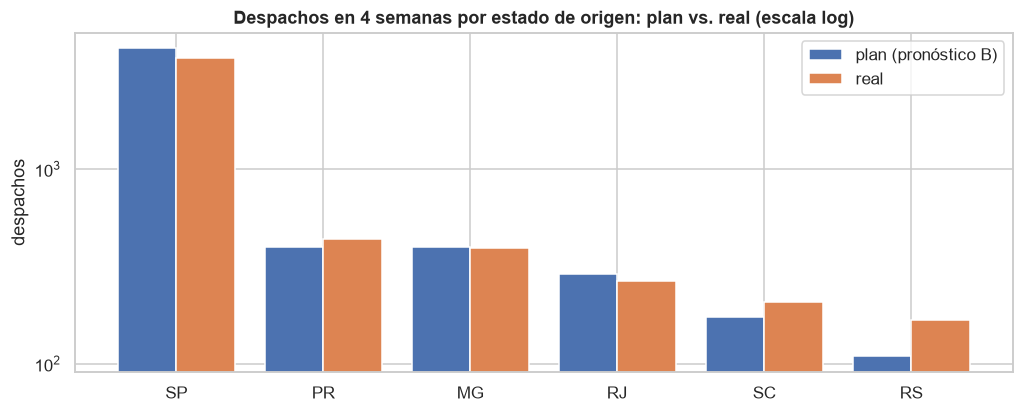

In [10]:
primer_dia = pronostico.index[0].date().isoformat()
fin_ventana = (pronostico.index[-1] + pd.Timedelta(days=1)).date().isoformat()
reales = consulta(con, "D_integracion/despachos_semanales_estado.sql", [primer_dia, primer_dia, fin_ventana])
reales = reales.pivot_table(index="estado_vendedor", columns="semana", values="despachos_reales", fill_value=0)

tasas = participacion.set_index("estado_vendedor")["despachos_por_orden"]
plan = pd.DataFrame(np.outer(tasas, ordenes_semana["pronostico"]), index=tasas.index, columns=range(1, 5))
plan_con_ordenes_reales = pd.DataFrame(np.outer(tasas, ordenes_semana["real"]), index=tasas.index, columns=range(1, 5))

principales = participacion["estado_vendedor"].head(6).tolist()
validacion = pd.DataFrame({
    "plan_4_semanas": plan.loc[principales].sum(axis=1),
    "real_4_semanas": reales.reindex(principales).fillna(0).sum(axis=1),
    "plan_si_B_acertara": plan_con_ordenes_reales.loc[principales].sum(axis=1),
})
validacion["error_plan_%"] = 100 * (validacion["plan_4_semanas"] - validacion["real_4_semanas"]) / validacion["real_4_semanas"]
validacion["error_solo_participacion_%"] = 100 * (validacion["plan_si_B_acertara"] - validacion["real_4_semanas"]) / validacion["real_4_semanas"]
total = pd.Series({
    "plan_4_semanas": plan.values.sum(), "real_4_semanas": reales.values.sum(),
    "plan_si_B_acertara": plan_con_ordenes_reales.values.sum(),
}, name="TOTAL")
total["error_plan_%"] = 100 * (total["plan_4_semanas"] - total["real_4_semanas"]) / total["real_4_semanas"]
total["error_solo_participacion_%"] = 100 * (total["plan_si_B_acertara"] - total["real_4_semanas"]) / total["real_4_semanas"]
validacion = pd.concat([validacion, total.to_frame().T])
display(validacion.round(1))

print("Plan semanal de despachos (estados principales):")
display(plan.loc[principales].round(0).astype(int).rename(columns=lambda s: f"semana {s}"))

fig, ax = plt.subplots(figsize=(11, 4))
x = np.arange(len(principales))
ax.bar(x - 0.2, validacion.loc[principales, "plan_4_semanas"], width=0.4, label="plan (pronóstico B)")
ax.bar(x + 0.2, validacion.loc[principales, "real_4_semanas"], width=0.4, label="real")
ax.set_xticks(x, principales)
ax.set_yscale("log")
ax.set(title="Despachos en 4 semanas por estado de origen: plan vs. real (escala log)", ylabel="despachos")
ax.legend()
guardar(fig, "plan_vs_real_estados", "D_integracion")
display(fig)
plt.close(fig)

**Lectura.**

- **Órdenes (Módulo B).** El pronóstico es casi plano: entre 1.371 y 1.441 órdenes por semana. La realidad
  fue de 1.328, 1.067, 1.185 y 1.790. El error semanal va de +3 % a +35 % (por la caída de julio) y −22 % (por
  el repunte de la semana 4), pero en las 4 semanas se compensa (+5 %). La suma de los techos diarios del
  90 % (2.119–2.189 por semana) nunca fue superada.
- **Despachos por estado.** El plan total de 4 semanas (5.753 despachos) supera al real (5.442) en un 5,7 %.
  Si B hubiera acertado las órdenes exactas, el error total sería del 0,3 %. Es decir, a nivel nacional el
  error viene del pronóstico de órdenes, no de los despachos por orden.
- **Por estado** el panorama cambia. SP queda sobreplanificado (+12,6 %; +6,8 % solo por participación) y
  los estados pequeños quedan cortos: SC −17 %, RS −35 %. Su participación cambió entre la ventana histórica
  y la prueba, y con pocos despachos semanales (27–44) cualquier variación pesa mucho. En PR, MG y RJ el
  error de B y el de participación se compensan parcialmente (−9 %, +1 % y +8 %).

La integración muestra que el pronóstico de B sirve para dimensionar la capacidad **total** de 4 semanas.
Para repartirla por estado hace falta tratar aparte a los estados pequeños.

## 7. Caso de uso y limitaciones

**Cómo se operaría: plan de capacidad de 4 semanas.**
1. Cada lunes, con los datos hasta el domingo, se ejecuta el pronóstico de B para los 28 días siguientes y
   su techo del 90 %.
2. Con SQL se calculan los despachos por orden de cada estado de origen en las últimas 12 semanas, y se
   publica el plan semanal: en esta prueba, unos 1.000–1.070 despachos semanales desde SP, unos 100 desde
   PR y MG y unos 70 desde RJ.
3. Las transportadoras reservan capacidad base según el plan central y capacidad contingente hasta el
   techo del 90 %.
4. Cada día se compara lo real con lo pronosticado. Si una semana se desvía más de un 20 % (como en las
   semanas 2 y 4 de esta prueba), se adelanta el re-pronóstico en vez de esperar al lunes siguiente.

**Limitaciones.**
- **Deriva temporal y cambios de nivel.** El modelo se apoya en el nivel de las últimas 4 semanas y no
  anticipa caídas (julio de 2018, −35 % en la semana 2) ni repuntes (agosto, −22 %). Su peor error fue
  justamente un pico no previsto (370 reales frente a 233 pronosticadas).
- **Poco historial para la estacionalidad anual.** Con un año y medio de datos, `dias_a_black_friday` y
  `mes` aprenden un patrón de un solo año. Se recomienda limitar `dias_a_black_friday` a las semanas
  cercanas al evento, o quitarla, hasta tener más años.
- **Modelo interpretado frente a modelo recomendado.** D interpreta el LightGBM elegido antes de ver la
  prueba (el directo). En la prueba lo superaron el recursivo y el ingenuo estacional, así que el plan puede
  alimentarse con cualquiera de ellos: la integración no depende del modelo.
- **Cobertura del dataset.** El período útil termina el 21-ago-2018 por el corte de extracción, y los
  despachos se cuentan por fecha de compra, no por fecha real de envío. Las 775 órdenes sin ítems no
  generan despacho.
- **Sesgo geográfico.** SP concentra el 73 % de los despachos. El plan es fiable a nivel nacional y para
  SP, pero en los estados pequeños los errores llegan al 17–38 %. Para ellos conviene usar rangos o
  ventanas históricas más largas.
- **Intervalos.** Sumar los techos diarios del 90 % da un techo semanal conservador; no es un intervalo
  semanal del 90 %. Y SHAP explica el modelo, no causas: la caída de julio, por ejemplo, no se puede
  atribuir con estos datos.

In [11]:
con.close()